In [5]:
import numpy as np
import pickle
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

from stwhmm_jax_optimized import STWHMM, EMResult


sns.set_context("talk")

%matplotlib widget

In [6]:
observations = np.load("data/maze_clipped_spike_counts_pyr_only_Bilat_R02_20251106.npz")['observations']
time_bins = np.load("data/maze_clipped_spike_counts_pyr_only_Bilat_R02_20251106.npz")['time_bins']
print(observations.shape)
print(time_bins.shape)

(130600, 201)
(130600,)


Found 480 saved restarts


/tmp/ipykernel_3308692/1092748622.py:54: RuntimeWarning: divide by zero encountered in log
  log_T=np.log(data["T"]),
/tmp/ipykernel_3308692/1092748622.py:57: RuntimeWarning: divide by zero encountered in log
  log_pi=np.log(data["pi"]),


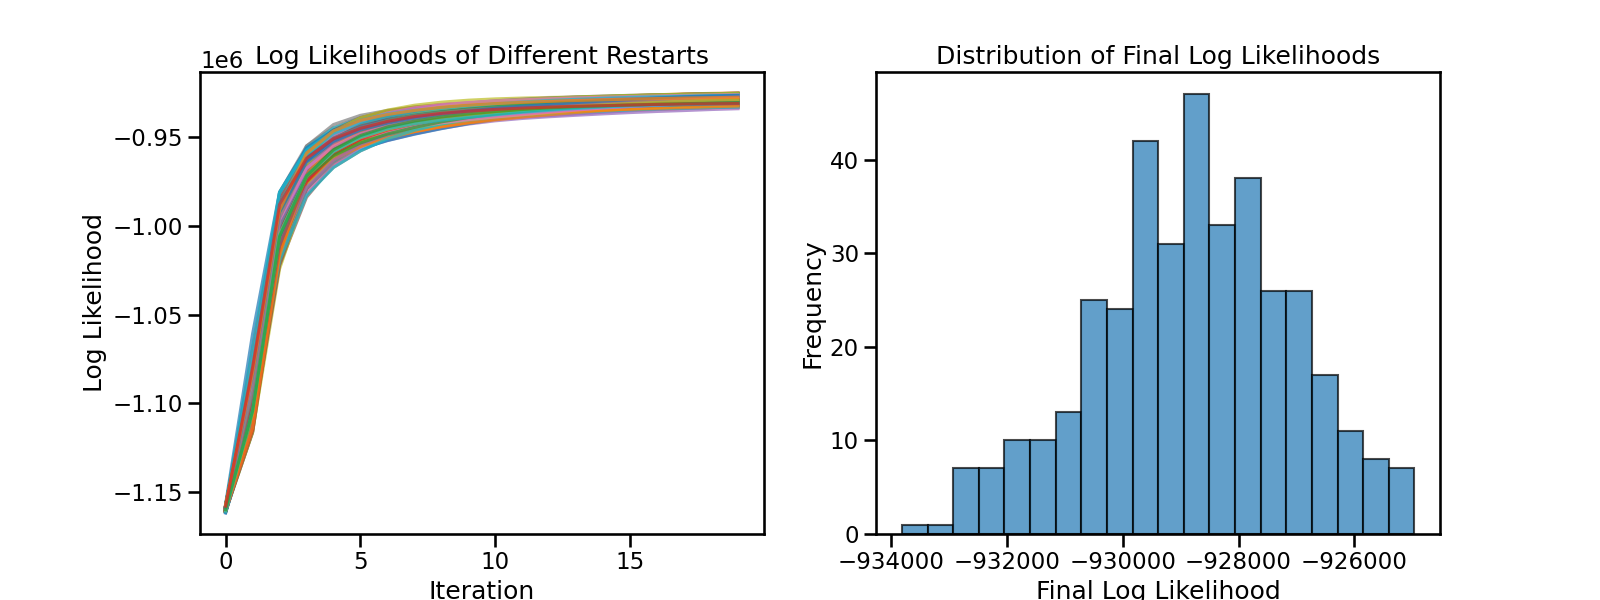


Best model
File: restart_66
Log likelihood: -924960.667475


In [ ]:
M = 101
S = 5
s = None


model = STWHMM(
    M=M,
    S=S,
    s=s,
    sequence_lengths=None,
    T_mask=None,
    H_mask=None,
    random_state=42,
    min_rate=1e-6
)

results_dir = Path(f"results_pyr_only_20ms_10iters/full_fit/N_{M}")

result_folders = os.listdir(results_dir)

print(f"Found {len(result_folders)} saved restarts")


# Find best saved restart
all_results = []

best_result = None
best_log_likelihood = -np.inf
best_file = None
final_llhs = []

fig, axs = plt.subplots(1,2,  figsize=(16, 6))

for folder in result_folders:

    result_file = results_dir / folder / "fitted_model.npz"

    if not result_file.exists():
        continue

    with np.load(result_file) as data:

        # Convert the saved .npz into an EMResult
        result = EMResult(
            log_likelihoods=np.asarray(data["training_likelihoods"]),
            losses=np.asarray(data["losses"]) if "losses" in data.files
                   else -np.asarray(data["training_likelihoods"]),
            converged=bool(data["converged"]) if "converged" in data.files
                      else False,
            n_iter=int(data["n_iter"]) if "n_iter" in data.files
                   else len(data["training_likelihoods"]),

            # Convert old probability-space parameters to log space
            log_T=np.log(data["T"]),
            log_H=np.log(data["H"]),
            log_Lambda=np.log(data["Lambda"]),
            log_pi=np.log(data["pi"]),
        )

    all_results.append(result)

    log_likelihoods = result.log_likelihoods
    axs[0].plot(log_likelihoods, alpha=0.7)

    log_likelihood = log_likelihoods[-1]
    final_llhs.append(log_likelihood)

    if log_likelihood > best_log_likelihood:
        best_log_likelihood = log_likelihood
        best_result = result
        best_file = folder


axs[0].ticklabel_format(style="sci", axis="y", scilimits=(0, 0))
axs[0].set_xlabel("Iteration")
axs[0].set_ylabel("Log Likelihood")
axs[0].set_title("Log Likelihoods of Different Restarts")
axs[1].hist(final_llhs, bins=20, alpha=0.7, edgecolor='black')
axs[1].ticklabel_format(style="sci", axis="y", scilimits=(0, 0))
axs[1].set_xlabel("Final Log Likelihood")
axs[1].set_ylabel("Frequency")
axs[1].set_title("Distribution of Final Log Likelihoods")
plt.show()


# Restore the best model
model.restore(best_result)

print("\nBest model")
print(f"File: {best_file}")
print(f"Log likelihood: {best_log_likelihood:.6f}")

In [14]:
state_sequence = model.viterbi(observations)

Z_hat = state_sequence[0]
tau_hat = state_sequence[1]

T_hat = model.T_
H_hat = model.H_
Lambda_hat = model.Lambda_
pi_hat = model.pi_

In [15]:
# find optimal sorting of the rows (neurons) of lambda_hat so that they peak in order
sort_order = np.argsort(np.argmax(Lambda_hat, axis=0))

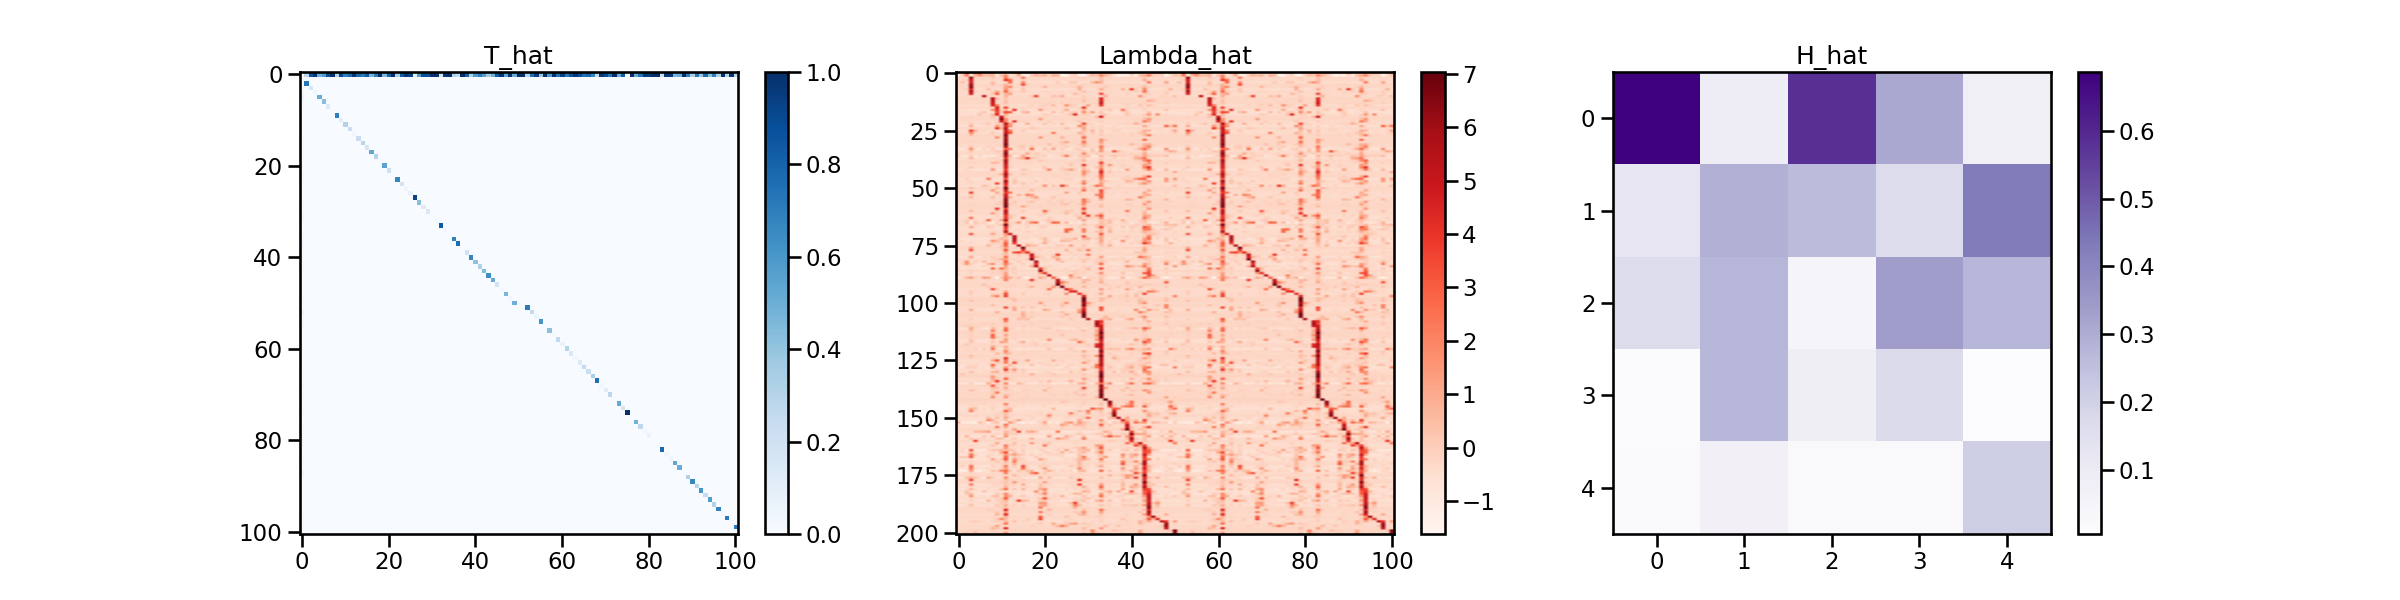

In [16]:
# plot the fitted matrices
plt.figure(figsize=(24, 6))
plt.subplot(1, 3, 1)
plt.imshow(T_hat, aspect='auto', cmap='Blues')
plt.colorbar()
plt.title('T_hat')

plt.subplot(1, 3, 2)
plt.imshow(stats.zscore(Lambda_hat[:, sort_order], axis=0).T, aspect='auto', cmap='Reds')
plt.colorbar()
plt.title('Lambda_hat')

plt.subplot(1, 3, 3)
plt.imshow(H_hat, aspect='auto', cmap='Purples')
plt.colorbar()
plt.title('H_hat')

plt.show()

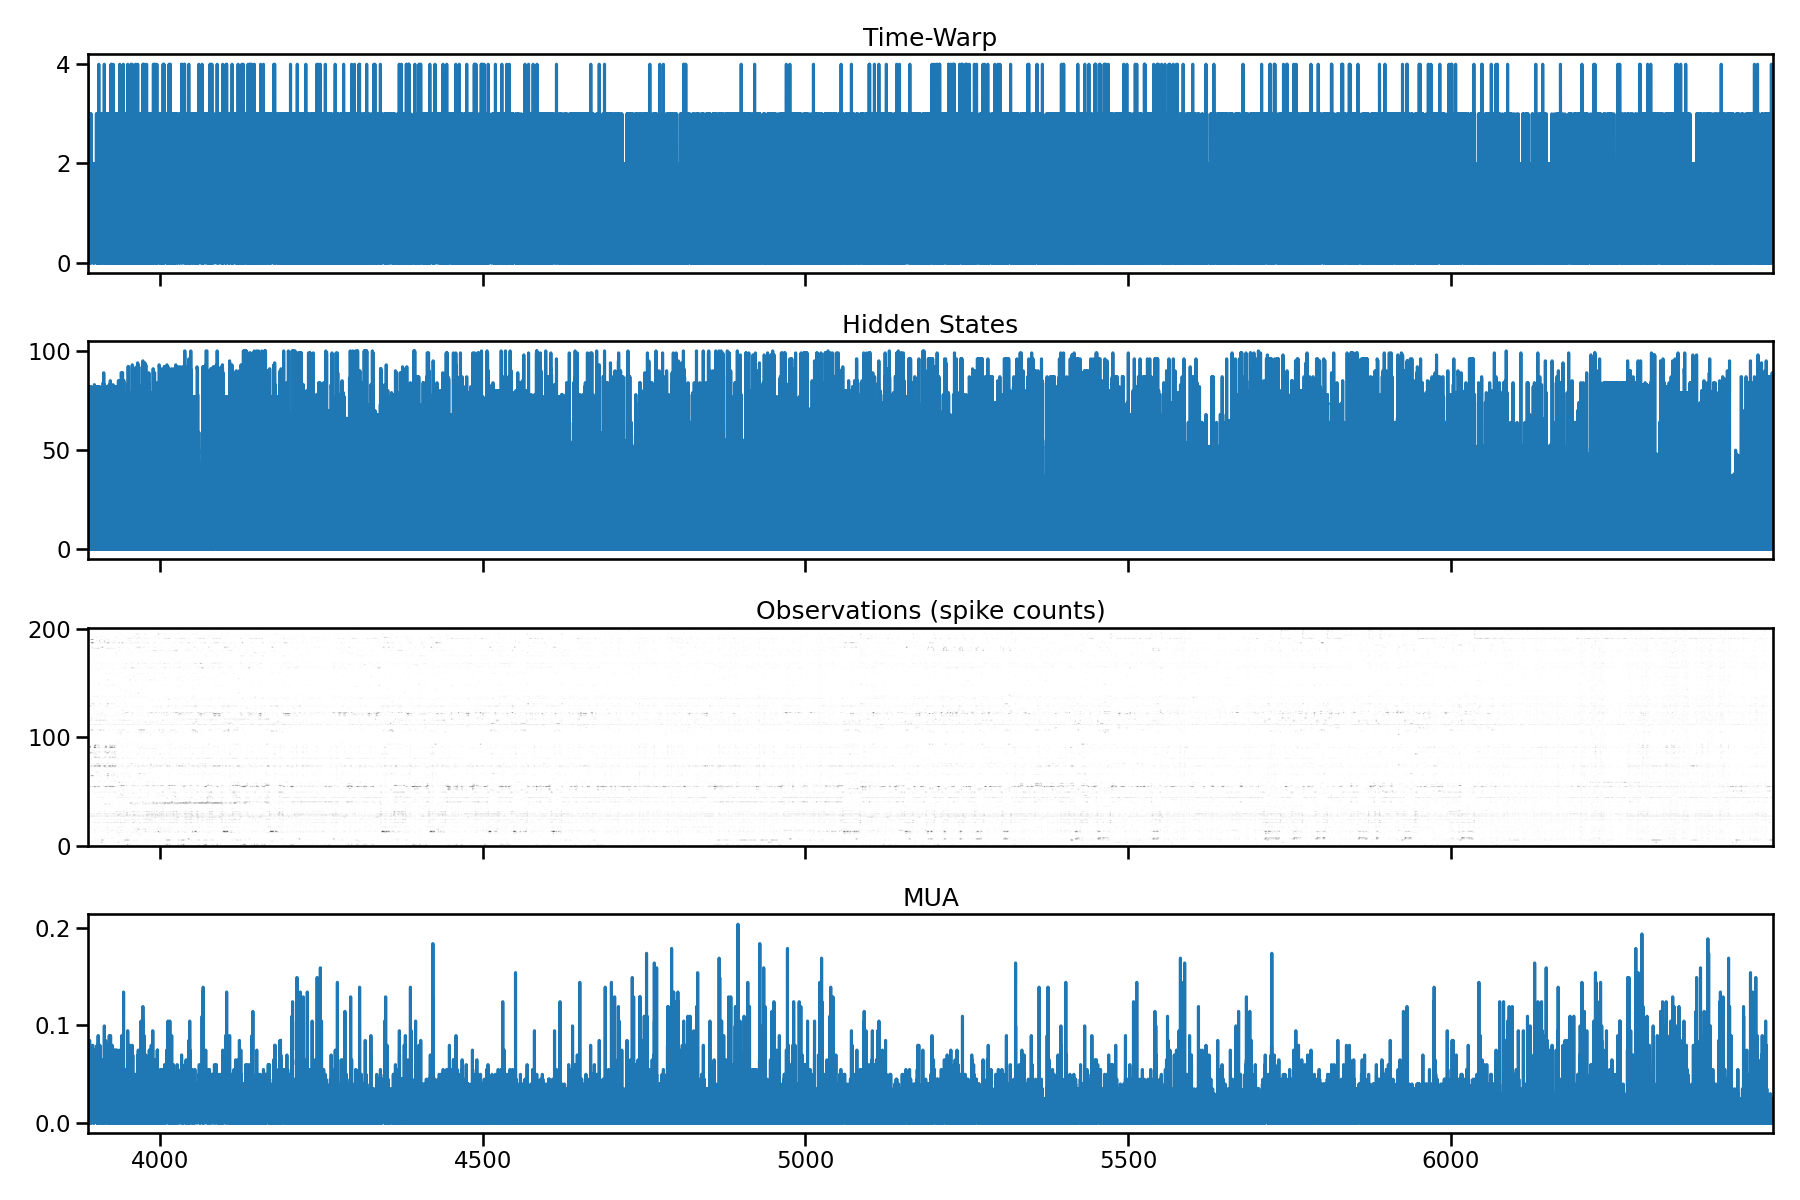

In [17]:



# plot the observations and the aligned hidden states and time-warps
fig, axs = plt.subplots(4, 1, figsize=(18, 12), sharex = True)
axs[0].plot(time_bins, state_sequence[1])
axs[0].set_title("Time-Warp")

axs[1].plot(time_bins, state_sequence[0])
axs[1].set_title("Hidden States")

axs[2].imshow(observations[:, sort_order].T, aspect='auto', cmap='Greys', vmin = 0, vmax = 1, extent=[time_bins[0], time_bins[-1], 0, observations.shape[1]])
axs[2].set_title("Observations (spike counts)")

axs[3].plot(time_bins, np.mean(observations, axis=1))
axs[3].set_title("MUA")

plt.tight_layout()
plt.show()